Task 2 Exploratory Data Analysis (EDA) 

Import Libraries 

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

Load Dataset 

In [5]:
df = pd.read_csv("CodeAlpha_Books_Dataset.csv")

print("Dataset Loaded Successfully!")

Dataset Loaded Successfully!


In [6]:
df.head()

,Book Name,Price,Rating,Availability
0,A Light in the Attic,51.77,3,In stock
1,Tipping the Velvet,53.74,1,In stock
2,Soumission,50.10,1,In stock
3,Sharp Objects,47.82,4,In stock
4,Sapiens: A Brief History of Humankind,54.23,5,In stock


Explore Dataset Structure

Dataset Shape

In [7]:
print("Rows and Columns:", df.shape)

Rows and Columns: (1000, 4)


Column Names

In [8]:
print(df.columns)

Index(['Book Name', 'Price', 'Rating', 'Availability'], dtype='str')


Data Types

In [9]:
df.dtypes

Book Name           str
Price           float64
Rating            int64
Availability        str
dtype: object

Dataset Information

In [10]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 4 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Book Name     1000 non-null   str    
 1   Price         1000 non-null   float64
 2   Rating        1000 non-null   int64  
 3   Availability  1000 non-null   str    
dtypes: float64(1), int64(1), str(2)
memory usage: 31.4 KB


Statistical Summary

In [11]:
df.describe()

,Price,Rating
count,1000.00000,1000.000000
mean,35.07035,2.923000
std,14.44669,1.434967
min,10.00000,1.000000
25%,22.10750,2.000000
50%,35.98000,3.000000
75%,47.45750,4.000000
max,59.99000,5.000000


Data Quality Check

Missing Values

In [12]:
print(df.isnull().sum())

Book Name       0
Price           0
Rating          0
Availability    0
dtype: int64


Duplicate Records

In [13]:
print("Duplicate Rows:", df.duplicated().sum())

print("Duplicate Book Names:", df["Book Name"].duplicated().sum())

Duplicate Rows: 0
Duplicate Book Names: 1


Unique Values

In [14]:
print("Unique Book Names:", df["Book Name"].nunique())

print("Unique Ratings:", df["Rating"].unique())

print("Availability:", df["Availability"].unique())

Unique Book Names: 999
Unique Ratings: [3 1 4 5 2]
Availability: <StringArray>
['In stock']
Length: 1, dtype: str


Univariate Analysis

Book Price Distribution

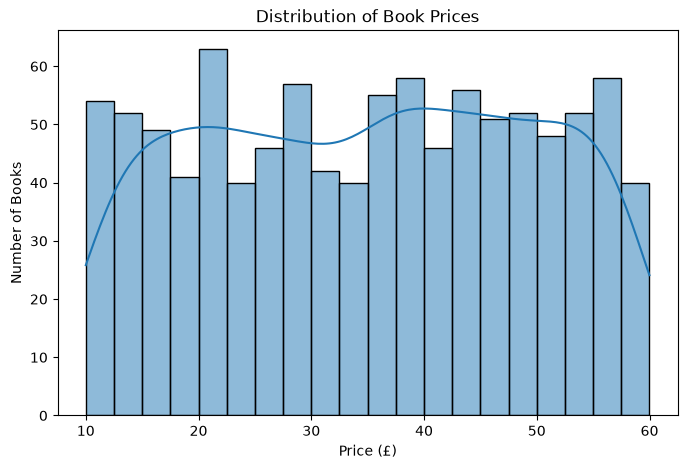

In [15]:
plt.figure(figsize=(8,5))

sns.histplot(df["Price"], bins=20, kde=True)

plt.title("Distribution of Book Prices")
plt.xlabel("Price (£)")
plt.ylabel("Number of Books")

plt.show()

Rating Distribution

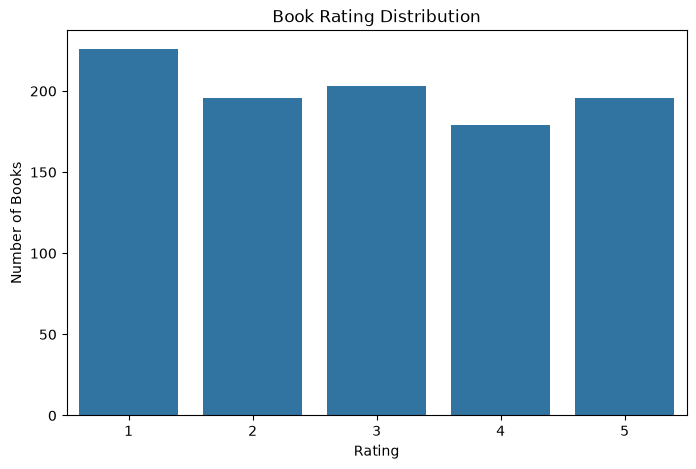

In [16]:
plt.figure(figsize=(8,5))

sns.countplot(data=df, x="Rating")

plt.title("Book Rating Distribution")
plt.xlabel("Rating")
plt.ylabel("Number of Books")

plt.show()

Availability Distribution

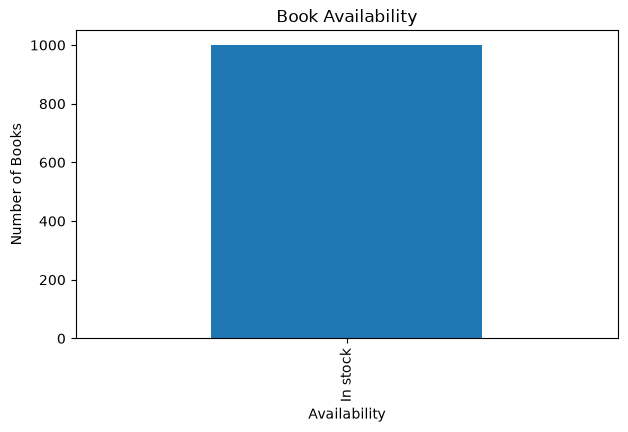

In [17]:
df["Availability"].value_counts().plot(
    kind="bar",
    figsize=(7,4)
)

plt.title("Book Availability")
plt.xlabel("Availability")
plt.ylabel("Number of Books")

plt.show()

Identify Trends and Patterns

Price vs Rating

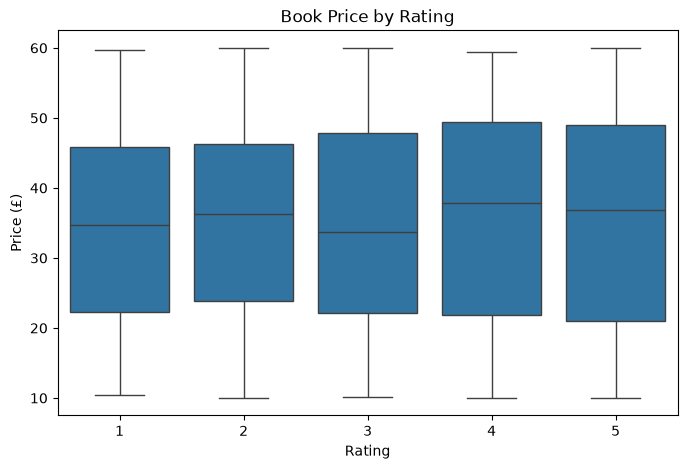

In [18]:
plt.figure(figsize=(8,5))

sns.boxplot(data=df, x="Rating", y="Price")

plt.title("Book Price by Rating")
plt.xlabel("Rating")
plt.ylabel("Price (£)")

plt.show()

Average Price by Rating

In [19]:
avg_price = df.groupby("Rating")["Price"].mean()

print(avg_price)

Rating
1    34.561195
2    34.810918
3    34.692020
4    36.093296
5    35.374490
Name: Price, dtype: float64


Detect Outliers

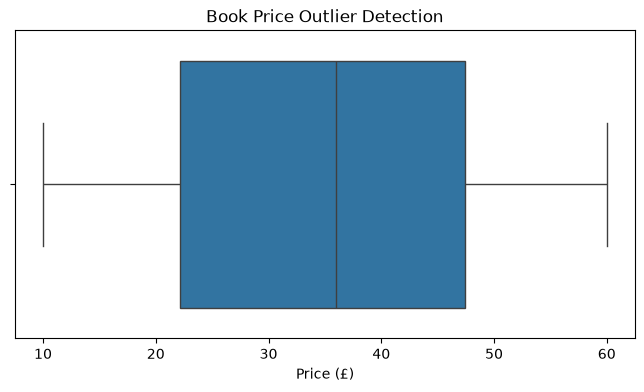

In [20]:
plt.figure(figsize=(8,4))

sns.boxplot(x=df["Price"])

plt.title("Book Price Outlier Detection")
plt.xlabel("Price (£)")

plt.show()

In [21]:
Q1 = df["Price"].quantile(0.25)

Q3 = df["Price"].quantile(0.75)

IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR

upper_limit = Q3 + 1.5 * IQR

outliers = df[
    (df["Price"] < lower_limit) |
    (df["Price"] > upper_limit)
]

print("Total Outliers:", len(outliers))

outliers

Total Outliers: 0


,Book Name,Price,Rating,Availability


Test Hypothesis Using Kruskal-Wallis Statistical Test

In [22]:
from scipy.stats import kruskal

groups = [
    group["Price"].values
    for rating, group in df.groupby("Rating")
]

stat, p_value = kruskal(*groups)

print("Test Statistic:", stat)
print("P-value:", p_value)

if p_value < 0.05:
    print("Reject H0: Significant difference found.")
else:
    print("Fail to reject H0: No significant difference found.")

Test Statistic: 1.5641994390128426
P-value: 0.8152117099178201
Fail to reject H0: No significant difference found.


Final EDA Summary

In [23]:
print("========== EDA SUMMARY ==========")

print("Total Books:", len(df))

print("Average Price:", round(df["Price"].mean(), 2))

print("Highest Price:", df["Price"].max())

print("Lowest Price:", df["Price"].min())

print("Most Common Rating:",
      df["Rating"].mode()[0])

print("Missing Values:", df.isnull().sum().sum())

print("Duplicate Rows:", df.duplicated().sum())

print("=================================")

========== EDA SUMMARY ==========
Total Books: 1000
Average Price: 35.07
Highest Price: 59.99
Lowest Price: 10.0
Most Common Rating: 1
Missing Values: 0
Duplicate Rows: 0


### Statistical Analysis – Conclusion

The Kruskal-Wallis test was performed to examine whether book prices differ significantly across rating groups.

- Test Statistic: 1.5642
- P-value: 0.8152
- Significance Level: 0.05

Since the p-value is greater than 0.05, we fail to reject the null hypothesis.

**Conclusion:** There is no statistically significant evidence of a difference in book prices across different rating groups in this dataset.

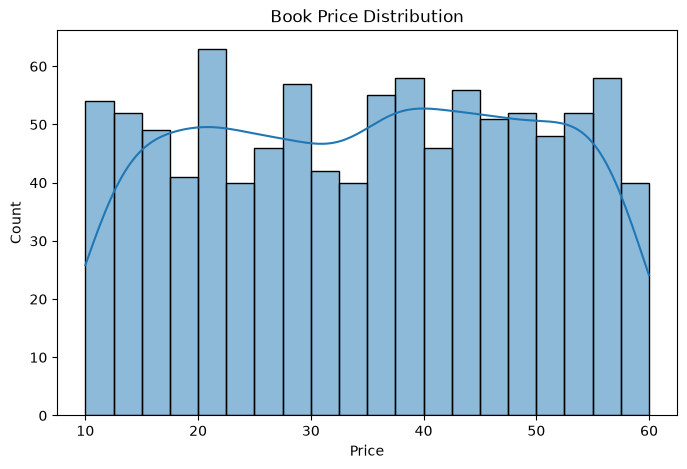

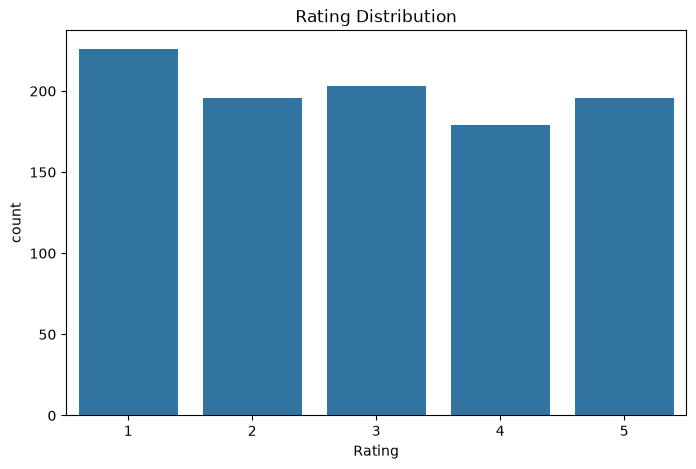

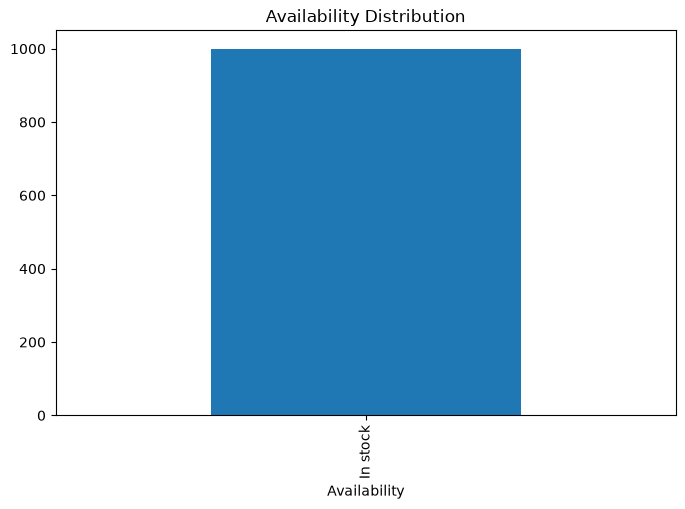

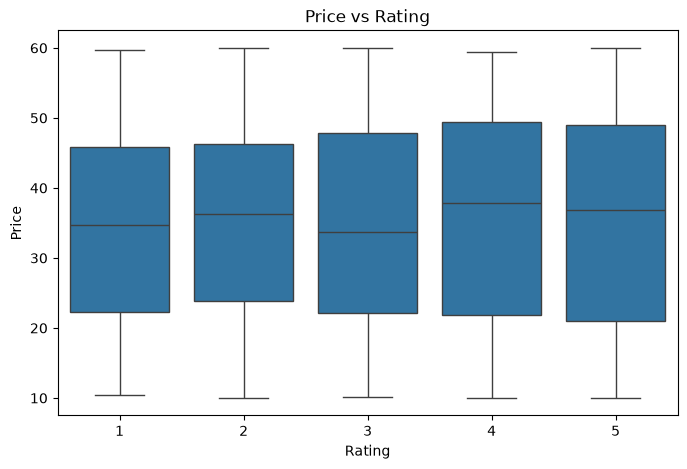

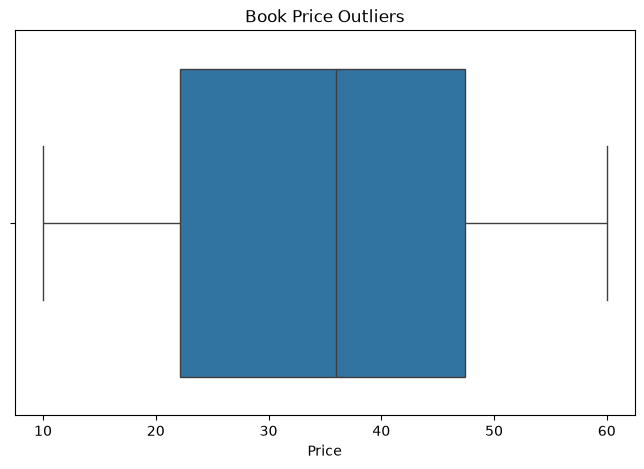

All Graphs Saved Successfully!


In [28]:
import os
import matplotlib.pyplot as plt
import seaborn as sns

os.makedirs("visualizations", exist_ok=True)

# 1. Book Price Distribution
plt.figure(figsize=(8,5))
sns.histplot(df["Price"], bins=20, kde=True)
plt.title("Book Price Distribution")
plt.savefig("visualizations/Book_Price_Distribution.png")
plt.show()

# 2. Rating Distribution
plt.figure(figsize=(8,5))
sns.countplot(data=df, x="Rating")
plt.title("Rating Distribution")
plt.savefig("visualizations/Rating_Distribution.png")
plt.show()

# 3. Availability Distribution
plt.figure(figsize=(8,5))
df["Availability"].value_counts().plot(kind="bar")
plt.title("Availability Distribution")
plt.savefig("visualizations/Availability_Distribution.png")
plt.show()

# 4. Price vs Rating
plt.figure(figsize=(8,5))
sns.boxplot(data=df, x="Rating", y="Price")
plt.title("Price vs Rating")
plt.savefig("visualizations/Price_vs_Rating.png")
plt.show()

# 5. Price Outliers
plt.figure(figsize=(8,5))
sns.boxplot(x=df["Price"])
plt.title("Book Price Outliers")
plt.savefig("visualizations/Price_Outliers.png")
plt.show()

print("All Graphs Saved Successfully!")